<a href="https://colab.research.google.com/github/Anggasaputraramadhan/PCVK/blob/main/week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MODUL P7 – SEGMENTASI CITRA DENGAN THRESHOLDING

A. Tujuan pembelajaran Setelah menyelesaikan praktikum ini, mahasiswa mampu:
1. Menjelaskan konsep segmentasi citra dan posisi thresholding di antara metode segmentasi lain (C2).
2. Menerapkan lima jenis global threshold, adaptive threshold, dan Otsu dengan OpenCV, serta mengimplementasikannya secara manual dengan NumPy (C3).
3. Memilih metode dan nilai threshold berdasarkan histogram dan kondisi pencahayaan citra (C4).
4. Mengevaluasi hasil segmentasi secara kuantitatif memakai IoU, Dice, dan pixel accuracy (C5).
5. Menerapkan K-Means untuk segmentasi warna dan merangkai segmentasi dengan pasca-proses morfologi dan OCR (C3).

B. ALAT DAN BAHAN:
1. PC/LAPTOP
2. Github
3. Google Colaboratory

C. ULASAN TEORI

C.1 Pengertian Segmentasi

Segmentasi citra adalah proses membagi sebuah citra digital menjadi beberapa area atau region yang memiliki kemiripan sifat visual seperti intensitas, warna, atau tekstur. Tujuannya adalah memisahkan bagian citra yang dianggap penting (objek) dari bagian yang kurang relevan (latar belakang). Hasilnya adalah citra yang terdiri dari beberapa segmen yang dapat dianalisis lebih lanjut secara terpisah.


Kelompok Metode segmentasi dapat dikelompokkan menurut prinsip kerjanya. Thresholding adalah metode berbasis intensitas yang paling sederhana dan menjadi dasar banyak metode lain.

In [ ]:
import pandas as pd
data = {
    "Kelompok": [
        "Thresholding",
        "Berbasis tepi",
        "Berbasis region",
        "Clustering",
        "Kontur aktif",
        "Deep learning"
    ],
    "Prinsip": [
        "Memisahkan piksel dengan batas intensitas (global, lokal, otomatis).",
        "Mencari diskontinuitas intensitas lalu menutup kontur.",
        "Mengelompokkan piksel bertetangga yang homogen.",
        "Mengelompokkan piksel di ruang fitur (warna, posisi, tekstur).",
        "Kurva yang bergerak meminimalkan fungsi energi.",
        "Jaringan dilatih dengan citra bertanda."
    ],
    "Contoh metode": [
        "Global, adaptive, Otsu, multi-Otsu, Triangle, Sauvola",
        "Sobel, Canny, Roberts",
        "Region growing, split and merge, watershed, mean shift",
        "K-Means, mean shift, GMM",
        "Snake, level set",
        "U-Net, Mask R-CNN, Segment Anything Model (SAM)"
    ]
}

df = pd.DataFrame(data)
display(df)

,Kelompok,Prinsip,Contoh metode
0,Thresholding,Memisahkan piksel dengan batas intensitas (glo...,"Global, adaptive, Otsu, multi-Otsu, Triangle, ..."
1,Berbasis tepi,Mencari diskontinuitas intensitas lalu menutup...,"Sobel, Canny, Roberts"
2,Berbasis region,Mengelompokkan piksel bertetangga yang homogen.,"Region growing, split and merge, watershed, me..."
3,Clustering,"Mengelompokkan piksel di ruang fitur (warna, p...","K-Means, mean shift, GMM"
4,Kontur aktif,Kurva yang bergerak meminimalkan fungsi energi.,"Snake, level set"
5,Deep learning,Jaringan dilatih dengan citra bertanda.,"U-Net, Mask R-CNN, Segment Anything Model (SAM)"


C.2 Pengertian Operasi Thresholding

Thresholding adalah bentuk metode paling sederhana dari segmentasi citra. Biasanya digunakan pada citra grayscale / warna dan ide dasarnya adalah bagaimana memisahkan antara objek foreground dengan objek backgroundnya.

Gambar berikut menunjukkan citra asli sebelum dan sesudah di lakukan thresholding.

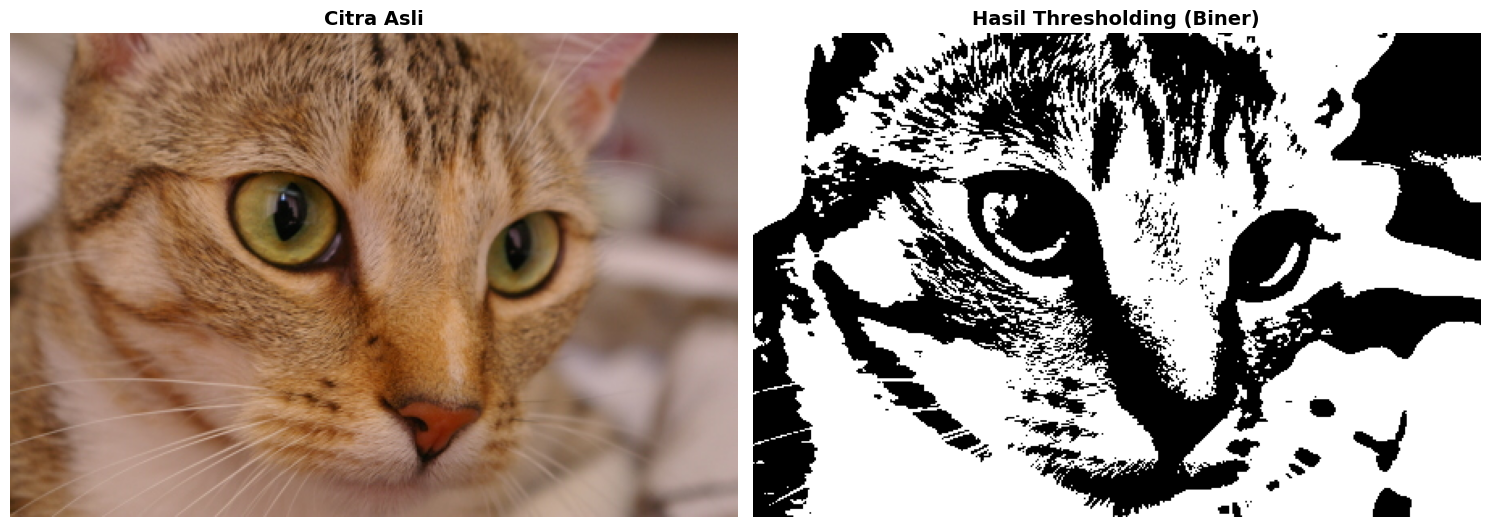

In [ ]:
import cv2
import matplotlib.pyplot as plt
import urllib.request

url = "blob:https://colab.research.google.com/f06411f0-bffb-4505-8762-e64f9d763d2c$0"
try:
    urllib.request.urlretrieve(url, "pemandangan_salju.jpg")
    img_bgr = cv2.imread("pemandangan_salju.jpg")
except:
    from skimage import data
    img_bgr = cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR)

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
img_display = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

threshold_value = 115
_, img_thresh = cv2.threshold(img_gray, threshold_value, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_display)
plt.title("Citra Asli", fontsize=14, fontweight='bold')
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_thresh, cmap="gray")
plt.title("Hasil Thresholding (Biner)", fontsize=14, fontweight='bold')
plt.axis("off")

plt.tight_layout()
plt.show()

Gambar 1. Citra kiri sebelum di threshold, citra kanan setelah dithreshold (citra binary)

Beberapa metode dari Threshold yang akan dibahas pada modul ini diantaranya:

a. Global Threshold

b. Adaptive Threshold

c. Otsu’s Threshold

d. Pengenalan Segmentasi Citra menggunakan K-Means

C.3 Global Threshold
Perhatikan histogram dari sebuah image yang ditunjukkan pada gambar berikut:

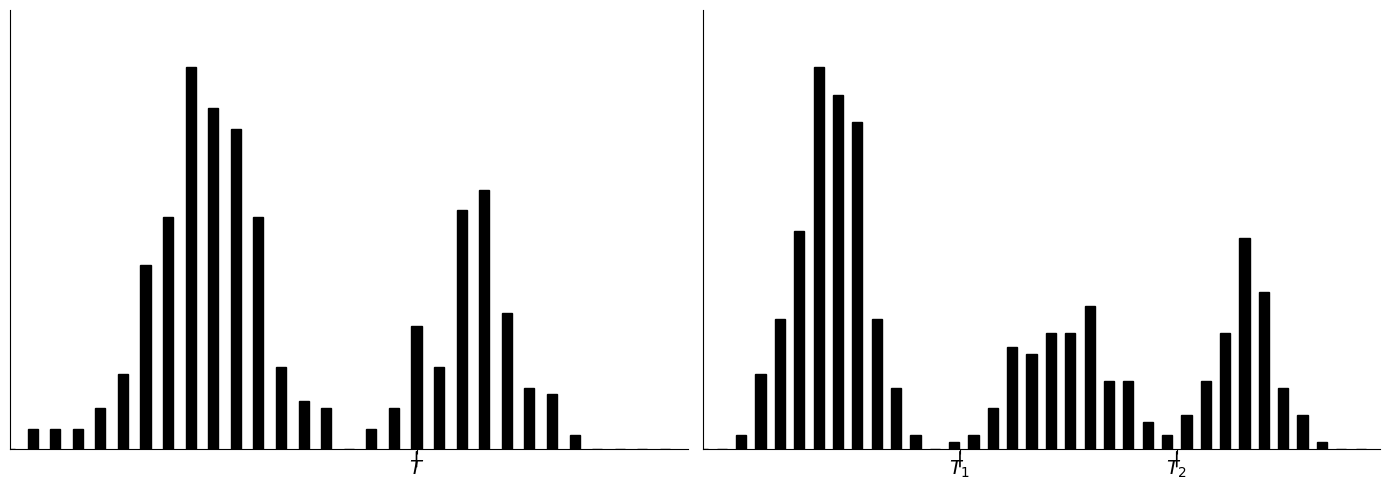

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
x1 = np.concatenate([
    np.random.normal(30, 8, 300),
    np.random.normal(70, 6, 150)
])
x1 = np.clip(x1, 5, 95)

counts1, bins1 = np.histogram(x1, bins=30, range=(0, 100))
ax1.bar(bins1[:-1], counts1, width=1.5, color='black', edgecolor='black')

ax1.set_xlim(0, 100)
ax1.set_ylim(0, max(counts1) * 1.15)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.set_xticks([60])
ax1.set_xticklabels(['$T$'], fontsize=14)
ax1.set_yticks([])

ax1.annotate('', xy=(60, 0), xytext=(60, -3),
            arrowprops=dict(arrowstyle="-", color='black', lw=1.2))

x2 = np.concatenate([
    np.random.normal(20, 5, 250),
    np.random.normal(55, 6, 120),
    np.random.normal(82, 4, 100)
])
x2 = np.clip(x2, 2, 98)

counts2, bins2 = np.histogram(x2, bins=35, range=(0, 100))
ax2.bar(bins2[:-1], counts2, width=1.5, color='black', edgecolor='black')

ax2.set_xlim(0, 100)
ax2.set_ylim(0, max(counts2) * 1.15)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_xticks([38, 70])
ax2.set_xticklabels(['$T_1$', '$T_2$'], fontsize=14)
ax2.set_yticks([])

ax2.annotate('', xy=(38, 0), xytext=(38, -3),
            arrowprops=dict(arrowstyle="-", color='black', lw=1.2))
ax2.annotate('', xy=(70, 0), xytext=(70, -3),
            arrowprops=dict(arrowstyle="-", color='black', lw=1.2))

plt.tight_layout()
plt.show()

Gambar 2. Intensitas histogram dapat dipisahkan dengan 1 Threshold (a) atau multiple Threshold (b)

Dianggap bahwa gambar diatas adalah histogram dari citra f(x,y), yang terdiri dari object terang pada background gelap. Dengan asumsi bahwa object dan background memiliki nilai intensitas warna yang dapat dipisahkan dalam 2 grup dominan. Cara yang termudah dan paling jelas adalah dengan memilih nilai tertentu (Threshold, T) yang akan memisahkan dua grup tersebut. Tiap titik (x,y) dalam image dimana f(x,y) > T dapat diistilahkan dengan object point, sedangkan grup satunya disebut dengan background point. Dengan kata lain, citra tersegmentasi g(x,y) dituliskan sebagai berikut:

𝑔(𝑥,𝑦) = { 1     𝑗𝑖𝑘𝑎 𝑓(𝑥,𝑦) > 𝑇 0     𝑗𝑖𝑘𝑎 𝑓(𝑥,𝑦) ≤ 𝑇

Ketika T ditentukan secara konstanta pada keseluruhan citra, maka proses inilah yang disebut sebagai global thresholding. Ketika nilai T berubah-ubah dalam dalam proses satu citra, maka hal ini disebut dengan variable/adaptive thresholding.

Gambar 2(a) diatas menunjukkan permasalahan thresholding yang melibatkan 3 grup dominan. Diasumsikan bahwa ada  2 grup terang dan 1 grup gelap pada histogram tersebut. Proses multiple threholding akan mengelompokkan titik (x,y) sebagai background jika f(x,y) <= T1, ke grup object satu jika T1 < f(x,y) <= T2, dan object grup lain jika f(x,y) > T2. Atau dapat dituliskan sebagai berikut:

𝑎            𝑔(𝑥,𝑦) = { 𝑗𝑖𝑘𝑎 𝑓(𝑥,𝑦) > 𝑇2 𝑏   𝑗𝑖𝑘𝑎 𝑇1 < 𝑓(𝑥,𝑦) ≤ 𝑇2 𝑐             𝑗𝑖𝑘𝑎 𝑓(𝑥,𝑦) ≤ 𝑇1

Pada OpenCV telah disediakan library untuk Thresholding, baik itu Global, Adaptive, maupun Otsu Threshold. Berikut adalah beberapat Global Thresholding yang disediakan:

a. Binary Threshold

b. Binary-Inverted Threshold

c. Truncate Threshold

d. Threshold To Zero

e. Threshold To Zero-Inverted

Untuk mengilustrasikan cara kerja masing-masing threshold, perhatikan histogram dari image asli src(x,y) pada gambar 3 berikut. Garis horizontal biru menunjukkan nilai threshold (tetap).


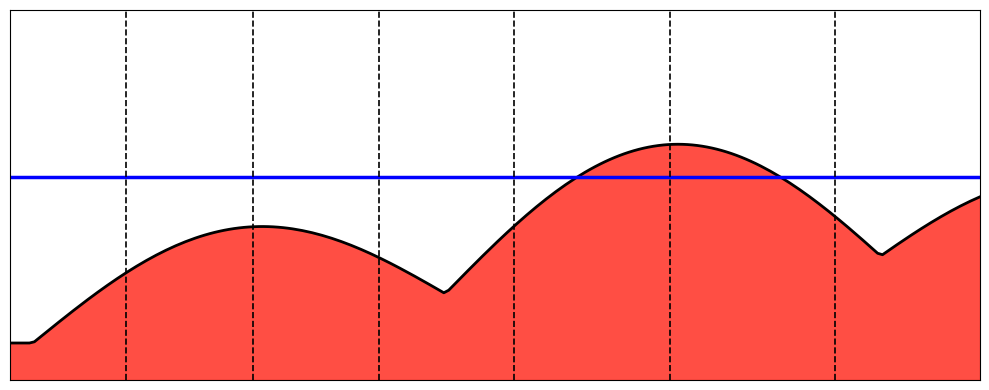

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 10, 200)
y = 2 + 3 * np.abs(np.sin(x * 0.7)) - 1.5 * np.cos(x * 0.4)
y = np.clip(y, 1, 9)
threshold_y = 5.5

fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)

vertical_lines = [1.2, 2.5, 3.8, 5.2, 6.8, 8.5]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()

Gambar 3. Histogram dari citra src(x,y)

a. Binary Threshold Binary Threshold seperti yang dijelaskan sebelumnya, merupakan threshold yang akan memisahkan dua grup warna. Untuk threshold ini, masing-masing kelompok warna akan diubah ke nilai gelap (hitam) untuk object yang dianggap background, dan diubah ke nilai terang (putih) untuk object yang dianggap foreground. Berikut adalah persamaannya:

𝑑𝑠𝑡(𝑥,𝑦) = {𝑚𝑎𝑥𝑉𝑎𝑙     𝑗𝑖𝑘𝑎 𝑠𝑟𝑐(𝑥,𝑦) > 𝑡ℎ𝑟𝑒𝑠ℎ 0                       𝑗𝑖𝑘𝑎 𝑙𝑎𝑖𝑛𝑛𝑦𝑎

Jadi jika nilai intensitas piksel warna pada src(x,y) lebih tinggi dari thresh, maka nilainya akan diubah menjadi maxVal. Selain itu akan diubah menjadi 0.

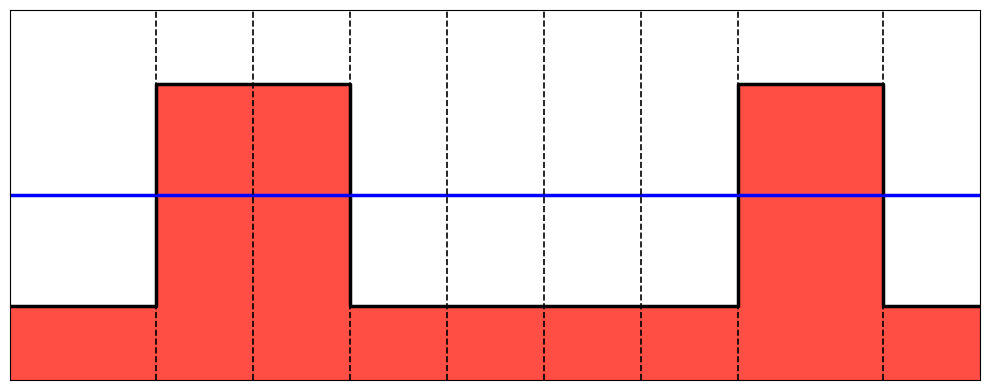

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 1.5, 1.5, 3.5, 3.5, 5.5, 5.5, 7.5, 7.5, 9.0, 9.0, 10.0])
y = np.array([2, 2,  8,   8,   2,   2,   2,   2,   8,   8,   2,   2])

threshold_y = 5.0

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2.5)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)

vertical_lines = [1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 9.0]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()

Gambar 4. Histogram hasil dari Binary Threshold

b. Binary-Inverted Threshold Threshold ini merupakan kebalikan dari Binary Threshold. Jika intensitas warna diatas Threshold, maka nilai akan diubah menjadi 0 dan sebaliknya. Berikut adalah persamaannya:

𝑑𝑠𝑡(𝑥,𝑦) = { 0                𝑚𝑎𝑥𝑉𝑎𝑙                       𝑗𝑖𝑘𝑎 𝑠𝑟𝑐(𝑥,𝑦) > 𝑡ℎ𝑟𝑒𝑠ℎ 𝑗𝑖𝑘𝑎 𝑙𝑎𝑖𝑛𝑛𝑦𝑎

Gambar 5 berikut merupakan histogram hasil Binary-Inverted Threshold.

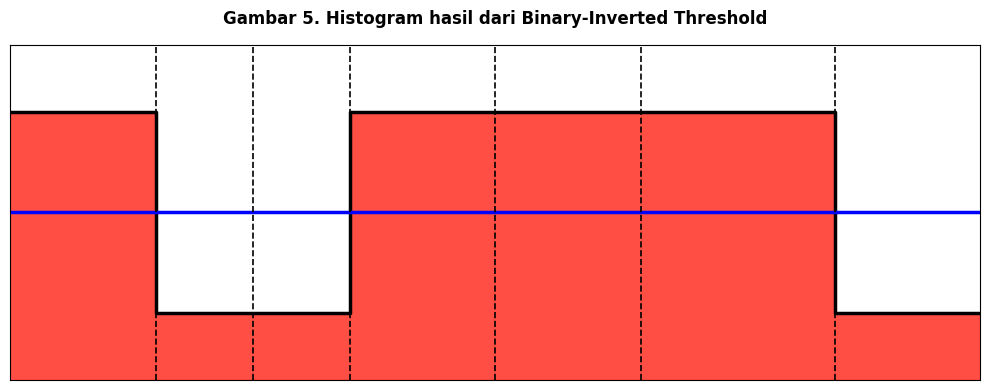

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 1.5, 1.5, 3.5, 3.5, 8.5, 8.5, 10.0])
y = np.array([8, 8,  2,   2,   8,   8,   2,   2])

threshold_y = 5.0
fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2.5)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)
vertical_lines = [1.5, 2.5, 3.5, 5.0, 6.5, 8.5]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.title("Gambar 5. Histogram hasil dari Binary-Inverted Threshold", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

c. Truncate Threshold Jika nilai intensitas warna src(x,y) lebih besar dari thresh, maka nilainya akan ditruncate. Berikut adalah persamaan dan Histogram hasilnya.

𝑑𝑠𝑡(𝑥,𝑦) = { 𝑡ℎ𝑟𝑒𝑠ℎ       𝑗𝑖𝑘𝑎 𝑠𝑟𝑐(𝑥,𝑦) > 𝑡ℎ𝑟𝑒𝑠ℎ 𝑠𝑟𝑐(𝑥, 𝑦)                        𝑗𝑖𝑘𝑎 𝑙𝑎𝑖𝑛𝑛𝑦𝑎

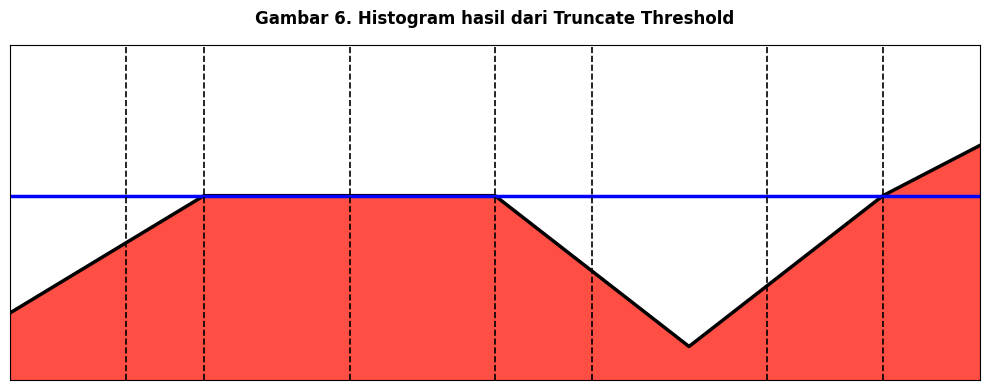

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 2, 3.5, 5, 7, 9, 10])
y = np.array([2, 5.5, 5.5, 5.5, 1, 5.5, 7])
threshold_y = 5.5

fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2.5)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)
vertical_lines = [1.2, 2, 3.5, 5, 6, 7.8, 9]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.title("Gambar 6. Histogram hasil dari Truncate Threshold", fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

d. Threshold To Zero Jika nilai src(x,y) lebih rendah dari nilai thresh, maka nilai pixel barunya akan diubah menjadi 0. Berikut adalah persamaan dan gambar Histogram hasil thresholdnya.

𝑑𝑠𝑡(𝑥,𝑦) = { 𝑠𝑟𝑐(𝑥,𝑦)    𝑗𝑖𝑘𝑎 𝑠𝑟𝑐(𝑥,𝑦) > 𝑡ℎ𝑟𝑒𝑠ℎ 0

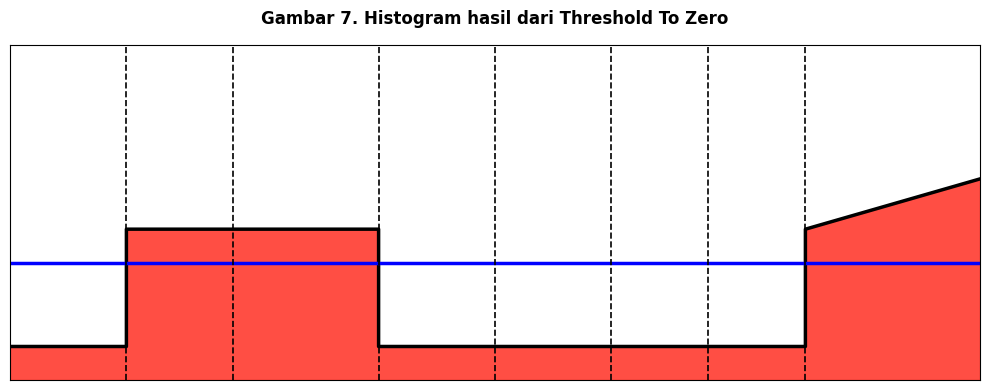

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 1.2, 1.2, 3.8, 3.8, 6.8, 6.8, 8.2, 8.2, 10])
y = np.array([1, 1,   4.5, 4.5, 1,   1,   1,   1,   4.5, 6])
threshold_y = 3.5

fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2.5)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)
vertical_lines = [1.2, 2.3, 3.8, 5.0, 6.2, 7.2, 8.2]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.title("Gambar 7. Histogram hasil dari Threshold To Zero", fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

e. Threshold To Zero – Inverted Jika nilai src(x,y) lebih besar dari nilai thresh, maka nilai pixel barunya akan diubah menjadi 0. Berikut adalah persamaan dan gambar Histogram hasil thresholdnya.

𝑗𝑖𝑘𝑎 𝑠𝑟𝑐(𝑥,𝑦) > 𝑡ℎ𝑟𝑒𝑠ℎ 𝑠𝑟𝑐(𝑥,𝑦)                       𝑗𝑖𝑘𝑎 𝑙𝑎𝑖𝑛𝑛𝑦𝑎

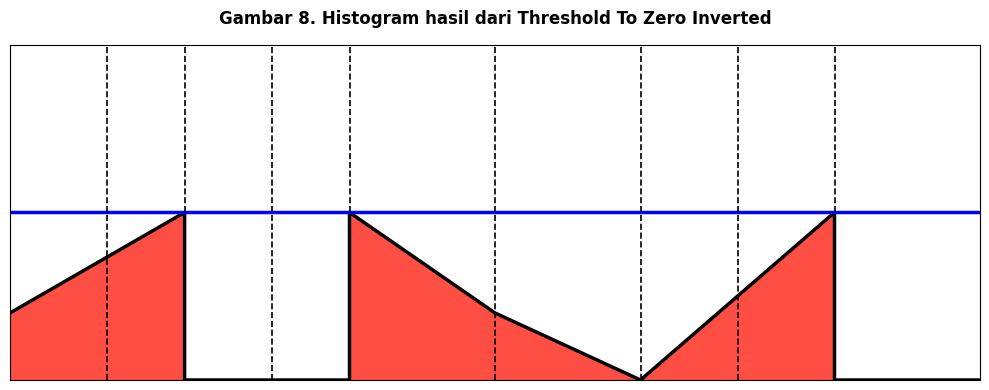

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 1.8, 1.8, 3.5, 3.5, 5, 6.5, 8.5, 8.5, 10])
y = np.array([2, 5,   0,   0,   5,   2,   0,   5,   0,   0])
threshold_y = 5.0

fig, ax = plt.subplots(figsize=(10, 4))

ax.fill_between(x, y, color='#ff3b30', alpha=0.9)
ax.plot(x, y, color='black', linewidth=2.5)
ax.axhline(y=threshold_y, color='blue', linewidth=2.5)

vertical_lines = [1.0, 1.8, 2.7, 3.5, 5.0, 6.5, 7.5, 8.5]
for vx in vertical_lines:
    ax.axvline(x=vx, color='black', linestyle='--', linewidth=1.2)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_xticks([])
ax.set_yticks([])

plt.title("Gambar 8. Histogram hasil dari Threshold To Zero Inverted", fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

Global threshold yang telah disebutkan diatas dapat digunakan secara langsung menggunakan library OpenCV cv.Threshold. berikut adalah link dokumentasinya:

https://docs.opencv.org/4.4.0/d7/d4d/tutorial_py_thresholding.html

Code Berikut menunjukkan penggunaan dari library OpenCV cv.Threshold

TypeError: Image data of dtype object cannot be converted to float

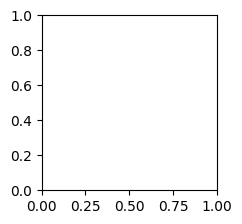

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

filename = ('/semester 5/Pengolahan Citra dan Visi Komputer/Modul P7-Segmentasi Citra dengan Thresholding')
img = cv.imread(filename)
thresh = 127
maxval = 255

ret, thresh1 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)
ret, thresh2 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY_INV)
ret, thresh3 = cv.threshold(img, thresh, maxval, cv.THRESH_TRUNC)
ret, thresh4 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO)
ret, thresh5 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO_INV)

titles = [
    'Original Image',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV',
]
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
  plt.subplot(2, 3, i + 1)
  plt.imshow(images[i], 'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]), plt.yticks([])
plt.show()

Gambar berikut menunjukkan perbedaan masing-masing global threshold yang merupakan keluaran dari code diatas. Seperti yang terlihat pada code tersebut, nilai Global thresholdnya adalah 127 dan nilai tersebut berlaku untuk keseluruhan image.

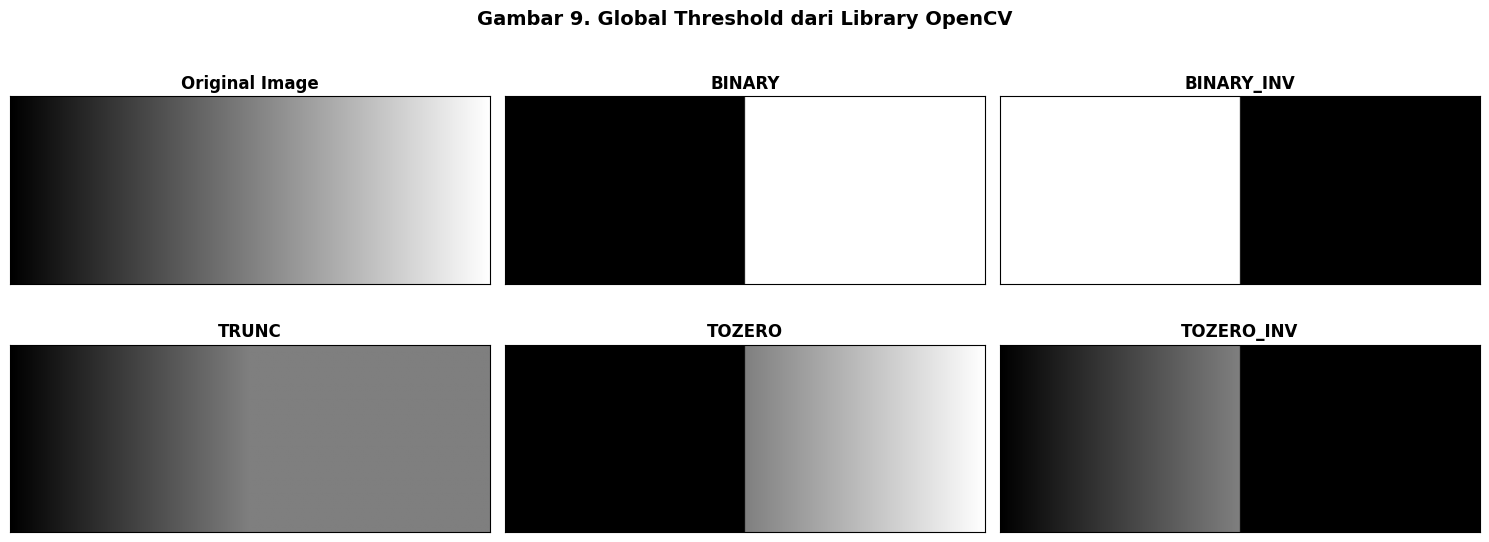

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = np.tile(np.arange(256, dtype=np.uint8), (100, 1))

thresh = 127
maxval = 255

ret, thresh1 = cv2.threshold(img, thresh, maxval, cv2.THRESH_BINARY)
ret, thresh2 = cv2.threshold(img, thresh, maxval, cv2.THRESH_BINARY_INV)
ret, thresh3 = cv2.threshold(img, thresh, maxval, cv2.THRESH_TRUNC)
ret, thresh4 = cv2.threshold(img, thresh, maxval, cv2.THRESH_TOZERO)
ret, thresh5 = cv2.threshold(img, thresh, maxval, cv2.THRESH_TOZERO_INV)

titles = [
    'Original Image',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV',
]
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 6))
for i in range(len(images)):
  plt.subplot(2, 3, i + 1)
  plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
  plt.title(titles[i], fontsize=12, fontweight='bold')
  plt.xticks([]), plt.yticks([])

plt.suptitle(
    'Gambar 9. Global Threshold dari Library OpenCV',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

C.4 Adaptive Threshold

Pada bagian sebelumnya kita menggunakan global thresholding, yaitu satu nilai ambang T untuk seluruh citra. Pendekatan ini bekerja baik jika pencahayaan merata dan histogram memperlihatkan pemisahan yang jelas antara objek dan latar. Kita juga telah melihat bahwa ia dapat gagal: pada citra Lena low contrast (intensitas 85-108), threshold tetap 127 menghasilkan citra hitam seluruhnya. Otsu memperbaiki masalah tersebut dengan menghitung T dari histogram, tetapi hasilnya tetap satu nilai untuk seluruh citra.

Masalah lain muncul ketika pencahayaan tidak merata, misalnya foto dokumen yang separuhnya terkena bayangan, atau papan sudoku yang difoto dari samping dengan satu sisi lebih gelap. Pada kondisi ini tidak ada satu nilai T yang cocok untuk semua bagian: T yang tepat di area terang akan menghapus tulisan di area gelap, dan sebaliknya.

Adaptive threshold (thresholding adaptif atau lokal) menjawab masalah itu dengan satu gagasan sederhana: setiap piksel mempunyai ambangnya sendiri, yang dihitung dari lingkungan di sekitar piksel tersebut.

Konsep Dasar

Pada global threshold, keputusan untuk piksel I(x, y) adalah:
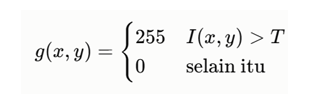

Pada adaptive threshold, T bukan lagi konstanta, melainkan fungsi posisi:
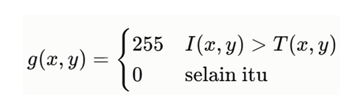

Nilai T(x, y) dihitung dari jendela (window) berukuran b × b yang berpusat di piksel (x, y). Piksel dibandingkan dengan keadaan lokalnya, bukan dengan nilai global. Dengan demikian, piksel yang lebih terang daripada lingkungannya menjadi putih, dan yang lebih gelap menjadi hitam, walaupun nilai absolutnya berbeda di bagian citra yang berlainan.

Cara Menghitung Ambang Lokal
Beberapa cara umum menentukan T(x, y):
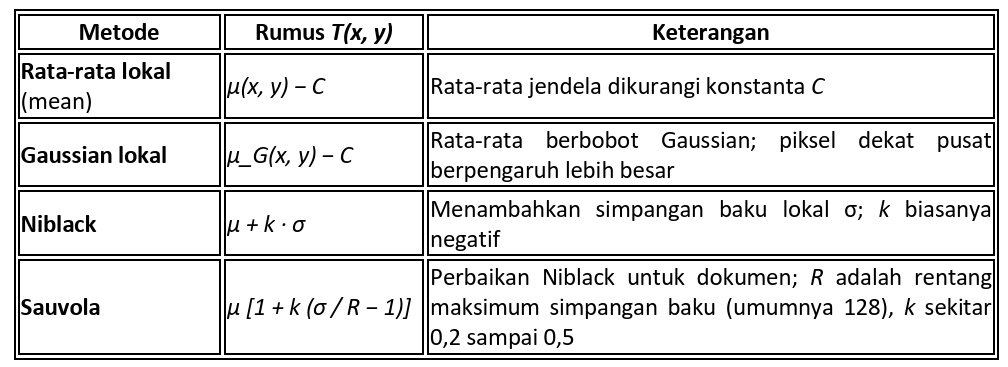

Praktikum ini memakai dua yang pertama (ADAPTIVE_THRESH_MEAN_C dan ADAPTIVE_THRESH_GAUSSIAN_C pada OpenCV). Niblack dan Sauvola tersedia di skimage.filters sebagai pengayaan.  Di OpenCV seluruh proses ini dikerjakan oleh satu fungsi: cv.adaptiveThreshold(citra, 255, metode, jenis, blockSize, C).

Dua parameter utama
1. Ukuran blok (block size, b)
Ukuran jendela, harus ganjil (misalnya 11, 31, 51). Ukuran ini menentukan seberapa "lokal" keputusannya:
- b terlalu kecil: jendela hanya mencakup sedikit piksel, sehingga T mengikuti noise dan tekstur halus. Hasilnya berbintik, dan bagian dalam objek yang besar bisa berlubang.
b terlalu besar: perilakunya mendekati global threshold, sehingga keunggulan adaptifnya hilang.
- Aturan praktis: b sedikit lebih besar daripada objek terbesar yang ingin dipertahankan (misalnya lebih besar dari lebar goresan huruf).

2. Konstanta C
Nilai yang dikurangkan dari rata-rata lokal. Fungsinya menentukan seberapa jauh piksel harus lebih terang daripada rata-rata lingkungannya agar dianggap putih:
- C = 0: piksel sedikit di atas rata-rata langsung menjadi putih, sehingga area yang homogen (misalnya latar polos) penuh bintik noise karena nilainya berfluktuasi di sekitar rataratanya sendiri.
- C > 0: ambang diturunkan, sehingga area homogen menjadi bersih (putih), dan hanya piksel yang cukup gelap yang dianggap objek.
- C terlalu besar: objek yang kontrasnya tipis ikut hilang.

Untuk citra low contrast, C perlu dipilih kecil. Misalnya pada citra Lena yang rentangnya hanya 24 level, C sebesar 20 sudah lebih besar daripada seluruh rentang intensitasnya.

Langkah Algoritma
1. Ubah citra ke grayscale (dan, bila perlu, haluskan dengan Gaussian blur untuk mengurangi noise).
2. Pilih ukuran blok b (ganjil) dan konstanta C.
3. Untuk setiap piksel (x, y), hitung rata-rata (atau rata-rata Gaussian) intensitas pada jendela b × b di sekitarnya.
4. Hitung ambang lokal T(x, y) = rata-rata − C.
5. Bandingkan: jika I(x, y) > T(x, y) maka piksel menjadi putih, selain itu hitam.
6. Ulangi untuk seluruh piksel menghasilkan citra biner.

Berikut adalah contoh code untuk Adaptive Threshold:
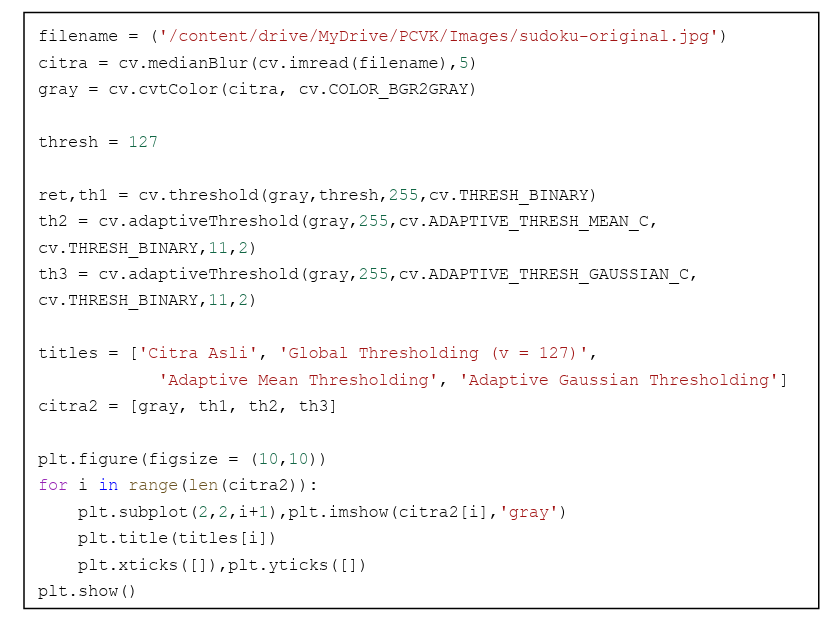

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import cv2 as cv

filename = '/Semester 5/Pengolahan Citra dan Visi Komputer/Images/sudoku-original.jpg'
img_raw = cv.imread(filename)
if img_raw is None:
  print(
      f"Error: File tidak ditemukan di path '{filename}'. Periksa kembali"
      ' nama folder atau file Anda!'
  )
else:
  citra = cv.medianBlur(img_raw, 5)
  gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)
  print('Gambar berhasil dimuat dan diproses!')

Error: File tidak ditemukan di path '/Semester 5/Pengolahan Citra dan Visi Komputer/Images/sudoku-original.jpg'. Periksa kembali nama folder atau file Anda!


Berikut adalah gambar hasil dari code tersebut:

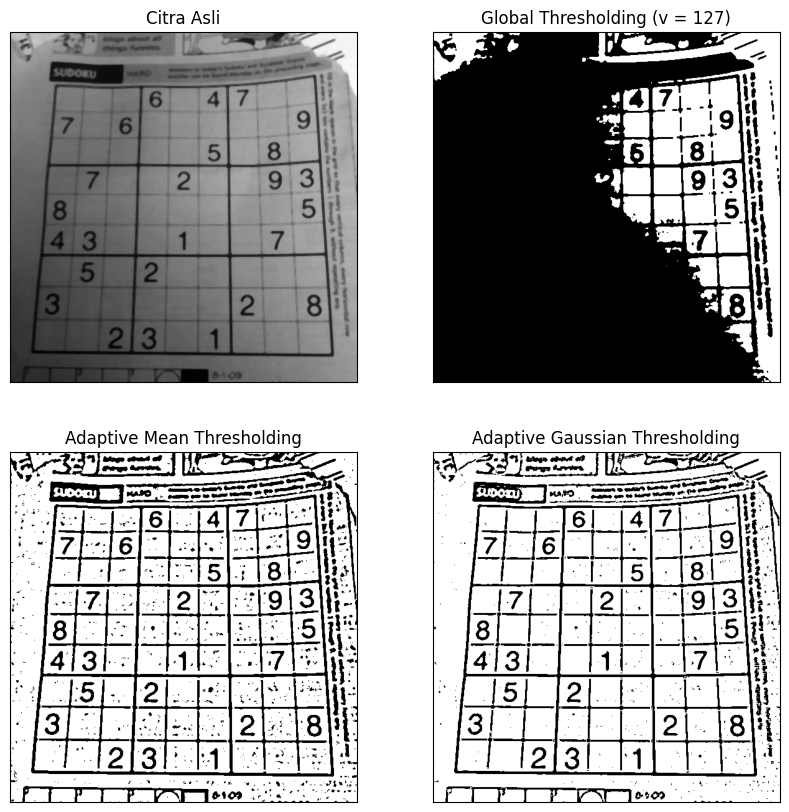

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import urllib.request
import os

filename = '/Semester 5/Pengolahan Citra dan Visi Komputer/Images/sudoku-original.jpg'
if not os.path.exists(filename):
    os.makedirs(os.path.dirname(filename), exist_ok=True)
    try:
        url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png"
        urllib.request.urlretrieve(url, filename)
    except:
        filename = 'sudoku-original.jpg'
        url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png"
        urllib.request.urlretrieve(url, filename)

img_raw = cv.imread(filename)
if img_raw is None:
    raise ValueError(f"File gambar tidak ditemukan di path: {filename}. Pastikan Google Drive sudah di-mount!")

citra = cv.medianBlur(img_raw, 5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127

ret, th1 = cv.threshold(gray, thresh, 255, cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(
    gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2
)
th3 = cv.adaptiveThreshold(
    gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2
)

titles = [
    'Citra Asli',
    'Global Thresholding (v = 127)',
    'Adaptive Mean Thresholding',
    'Adaptive Gaussian Thresholding',
]
citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(10, 10))
for i in range(len(citra2)):
  plt.subplot(2, 2, i + 1)
  plt.imshow(citra2[i], 'gray')
  plt.title(titles[i])
  plt.xticks([]), plt.yticks([])
plt.show()

Kelebihan dan Keterbatasan

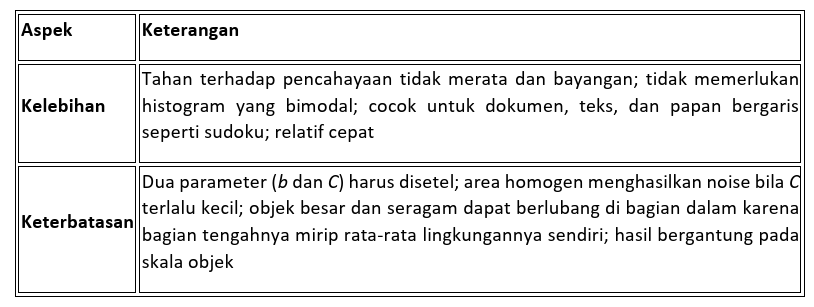

C.5 Otsu’s Threshold

Otsu’s threshold adalah metode segmentasi otomatis yang sangat populer, bahkan sampai hari ini pun masih sering digunakan sebagai standar metode binary threshold yang handal. Threshold ini dinamakan sesuai dengan nama penemunya yaitu Nobuyuki Otsu. Dalam bentuk yang paling sederhana, algoritma ini akan melakukan segmentasi pixel menjadi dua kelas, yaitu foreground dan background. Threshold ini ditentukan dengan meminimasikan intensitas variance intra-class, atau bisa juga dengan memaksimalkan variance inter-class.

Algoritma Otsu’s secara iteratif mencari threshold yang terkecil dari variance intra-class, yang didefinisikan sebagai jumlah bobot dari variance dua class:

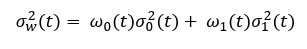

Bobot 𝜔0 dan 𝜔1adalah probabilitas dari 2 class yang dipisahkan oleh threshold t. 𝜎02dan 𝜎12adalah variance dari masing-masing class.
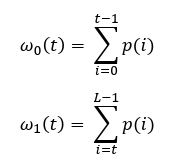

Mencari nilai minimal dari variance intra-class ekivalen dengan mencari nilai maksimal dari variance inter-class.
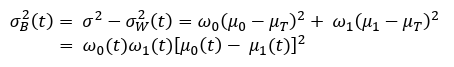

Dimana nilai mean class 𝜇0(𝑡), 𝜇1(𝑡), dan 𝜇𝑇 adalah:
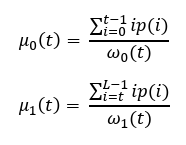
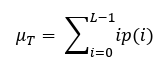

Perhatikan contoh perhitungan algoritma Otsu’s berikut:
Gambar berikut menunjukkan sebuah image resolusi 6x6 dan terdiri dari 6 warna, beserta histogramnya.
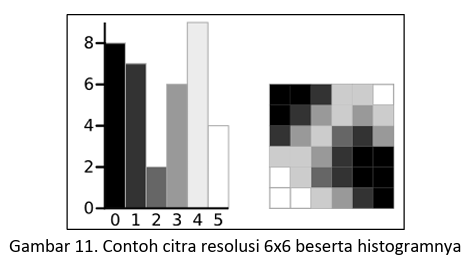

Dari gambar diatas, lakukan perhitungan Weight, Mean, Variance untuk tiap background dan foreground untuk tiap nilai threshold. Contoh berikut adalah perhitungan dengan nilai threshold = 3.
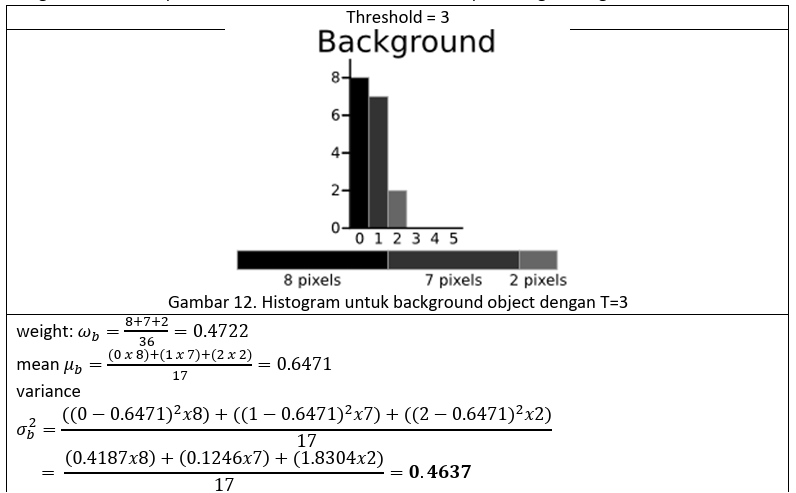
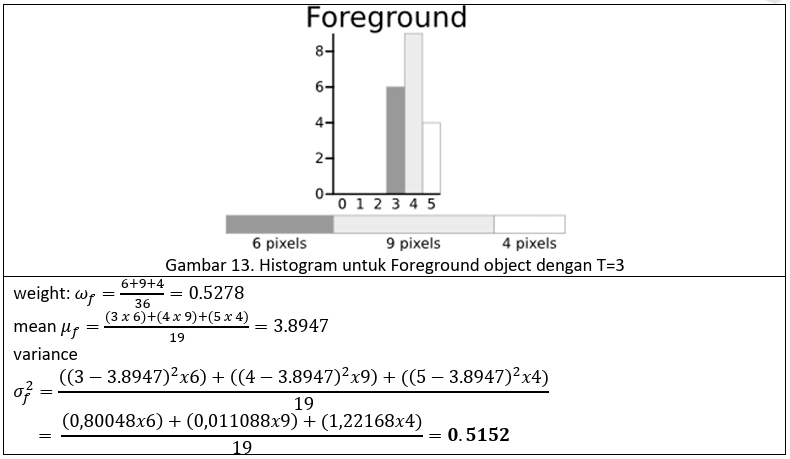

Selanjutnya nilai within class variance dari 2 variance (background dan foreground) dapat dihitung dengan :

Within class variance:

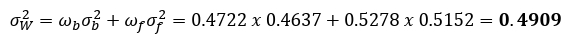
Perhitungan ini dilakukan untuk setiap nilai threshold yang mungkin (0 <= T <= 5). Nilai Within class variance terkecil akan menjadi threshold yang terpilih.
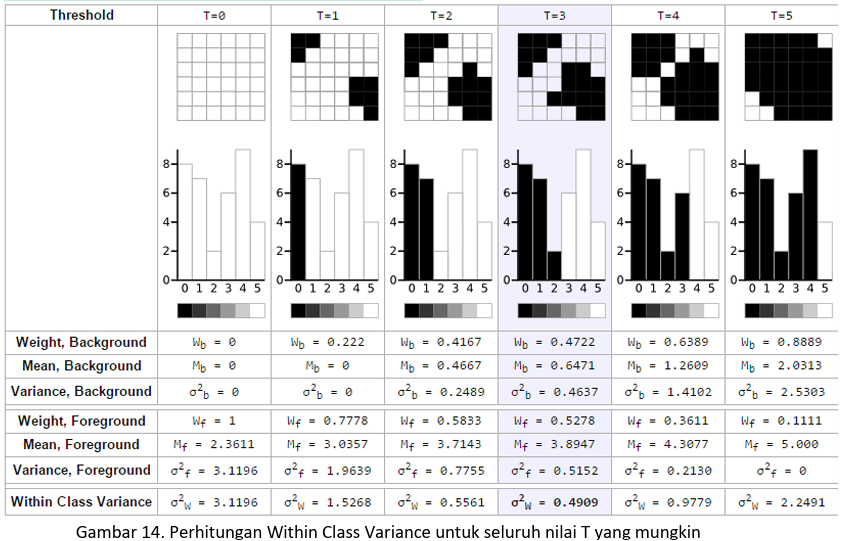

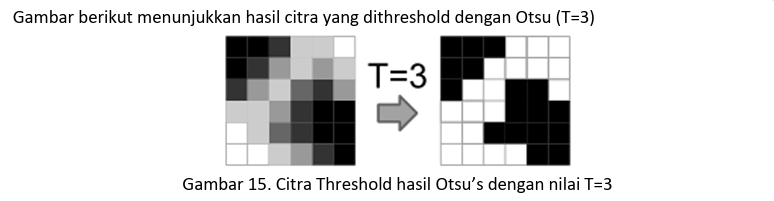

Penentuan nilai threshold yang terpilih juga bisa dilakukan menggunakan perhitungan Between class variance, dimana nilai Between class variance terbesar adalah threshold yang terpilih. Between class variance:
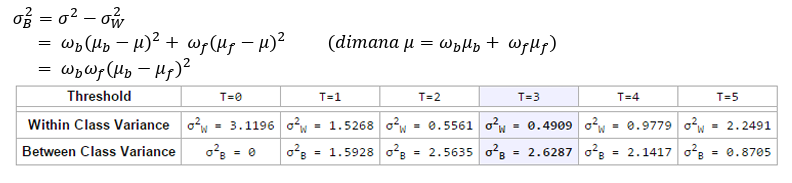

Otsu’s telah disediakan pula dalam library OpenCV (cv.THRESH_OTSU) yang biasanya dikombinasikan dengan binary threshold(cv.THRESH_BINARY). Library ini dipanggil dengan object cv.threshold. Berikut adalah code contoh penggunaan Otsu’s dengan library OpenCV.


/tmp/ipykernel_1520/281883292.py:34: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [50, 200])


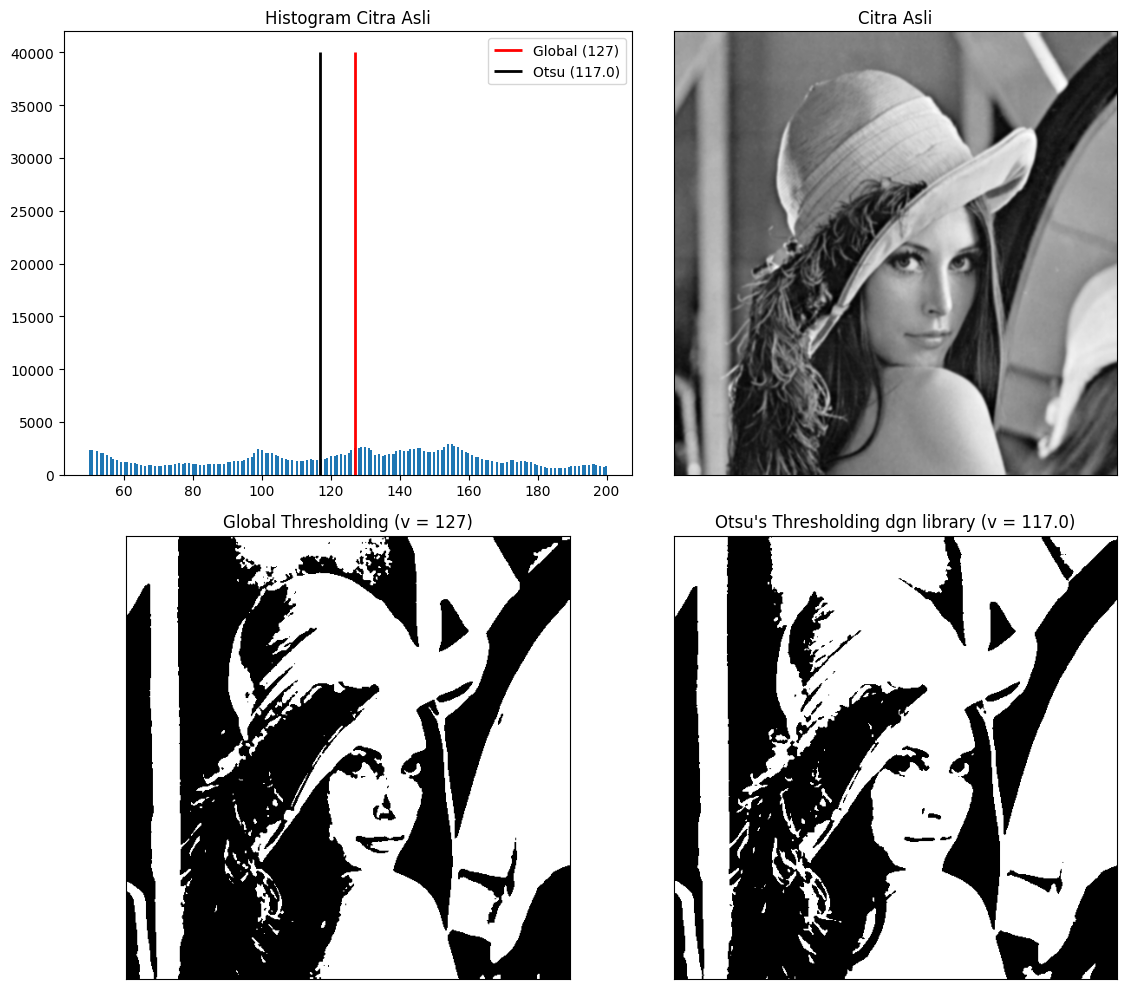

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import os
import urllib.request

filename = '/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg'
if not os.path.exists(filename):
    try:
        os.makedirs(os.path.dirname(filename), exist_ok=True)
    except:
        filename = 'lena_gs_lc2.jpg'

    if not os.path.exists(filename):
        print("Mengunduh gambar sampel 'lena.jpg' secara otomatis...")
        url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
        urllib.request.urlretrieve(url, filename)
img = cv.imread(filename, 0)
if img is None:
    filename = 'lena_gs_lc2.jpg'
    url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
    urllib.request.urlretrieve(url, filename)
    img = cv.imread(filename, 0)

blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
ret2, th2 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
x_label = "Otsu's Thresholding dgn library (v = " + str(ret2) + ")"
titles = ['Citra Asli', 'Global Thresholding (v = 127)', x_label]
citra3 = [blur, th1, th2]
plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1)
plt.hist(blur.ravel(), 256, [50, 200])
plt.vlines(ret, 0, 40000, colors='red', linewidth=2, label='Global (127)')
plt.vlines(ret2, 0, 40000, colors='black', linewidth=2, label=f'Otsu ({ret2})')
plt.title('Histogram Citra Asli')
plt.legend(loc='upper right')
for i in range(len(citra3)):
    plt.subplot(2, 2, i + 2)
    plt.imshow(citra3[i], cmap='gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Gambar 16. Citra hasil threshold menggunakan binary threshold dan Otsu’s

Code berikut akan menampilkan hasil dari threshold Otsu’s tanpa Gaussian Filter dan dengan menggunakan Gaussian Filter.
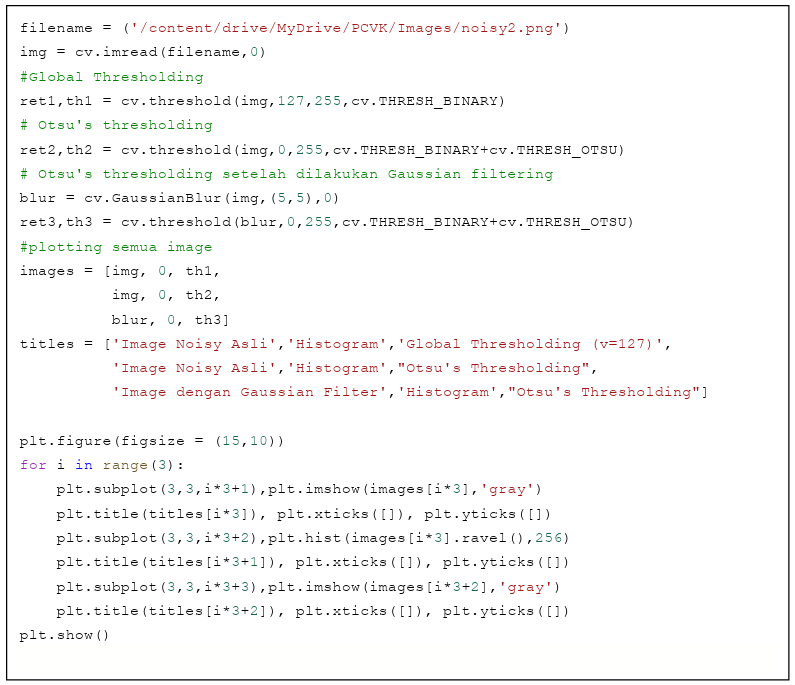

Gambar berikut menunjukkan hasil dari code diatas. Dapat disimpulkan bahwa dengan melakukan filtering terlebih dahulu terhadap citra masukan, hasil threshold Otsu’s dapat lebih baik.

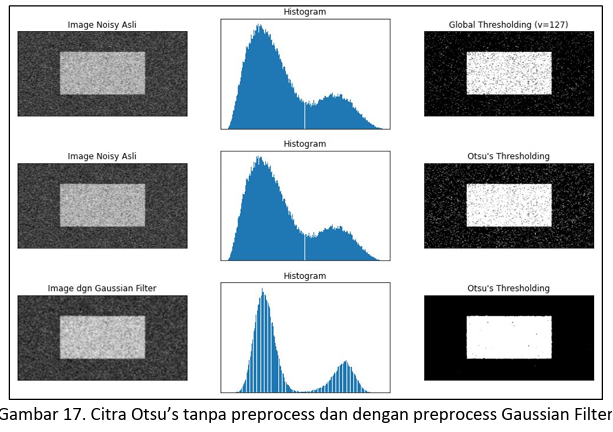

C.6 Segmentasi citra berbasis wilayah (Region-Based Segmentation)

Pada bagian sebelumnya, kita telah mempelajari segmentasi dengan thresholding, yaitu memisahkan objek dan latar belakang berdasarkan satu nilai ambang. Pendekatan tersebut bekerja dengan baik jika histogram citra memperlihatkan pemisahan yang jelas antara objek dan latar. Namun, kita juga telah melihat bahwa thresholding bisa gagal ketika kontras citra rendah, misalnya pada citra Lena dengan rentang intensitas 85-108, di mana threshold tetap 127 menghasilkan citra hitam seluruhnya.

Segmentasi berbasis wilayah menawarkan cara pandang yang berbeda. Alih-alih bertanya "apakah nilai piksel ini di atas atau di bawah ambang?", metode ini bertanya "apakah piksel ini mirip dengan tetangga-tetangganya?". Dengan demikian, citra dibagi menjadi beberapa wilayah (region) yang masing-masing terdiri dari piksel-piksel yang saling berdekatan dan memiliki karakteristik serupa.

Konsep Dasar

Secara formal, segmentasi citra I menjadi n region R₁, R₂, ..., Rₙ harus memenuhi syarat berikut:
1. Lengkap: gabungan seluruh region membentuk citra utuh, sehingga setiap piksel termasuk dalam satu region.
2. Terhubung: setiap region berupa kumpulan piksel yang saling bersebelahan.
3. Saling lepas: tidak ada piksel yang menjadi anggota dua region sekaligus.
4. Homogen: setiap region memenuhi predikat kesamaan P(Rᵢ) = TRUE.
5. Berbeda antar region: gabungan dua region yang bertetangga tidak memenuhi predikat kesamaan, yaitu P(Rᵢ ∪ Rⱼ) = FALSE.

Syarat ke-4 dan ke-5 inilah inti dari pendekatan berbasis wilayah. Region harus homogen di dalam dan berbeda dengan region di sekitarnya.

Ciri-ciri pendekatan ini

- Fokus pada kesamaan antar piksel tetangga. Keputusan pengelompokan didasarkan pada hubungan lokal antar piksel yang berdekatan, bukan pada nilai absolut piksel terhadap suatu ambang global.
- Menekankan keterhubungan area dibanding batas tepi. Metode berbasis tepi (edge-based) mencari tempat intensitas berubah drastis, sedangkan metode berbasis wilayah mencari area yang konsisten. Keduanya saling melengkapi.
- Biasanya diawali dari titik awal (seed point). Pada banyak metode, proses dimulai dari satu atau beberapa piksel acuan yang kemudian meluas ke piksel di sekitarnya selama kriteria kesamaan terpenuhi.
- Cocok untuk citra yang tidak memiliki kontras tegas namun area objek cukup homogen. Karena yang dinilai adalah kemiripan lokal, metode ini lebih tahan terhadap citra berkontras rendah dibandingkan threshold global.

Kriteria Kesamaan (Homogeneity Criteria)
Kriteria kesamaan adalah aturan yang menentukan apakah suatu piksel (atau region) boleh digabungkan ke dalam region yang sudah ada. Suatu piksel dianggap sesuai jika memenuhi salah satu kondisi berikut:
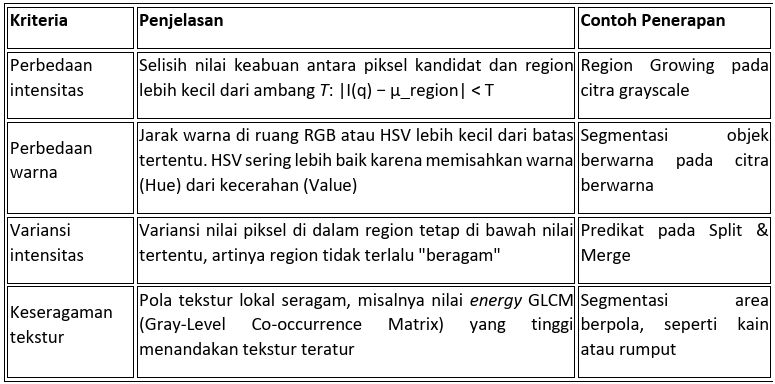

Pemilihan kriteria sangat memengaruhi hasil. Ambang yang terlalu ketat menghasilkan banyak region kecil (over-segmentation), sedangkan ambang yang terlalu longgar membuat objek berbeda menyatu menjadi satu region (under-segmentation).

Jenis Metode Segmentasi Berbasis Wilayah

Praktikum ini membahas empat metode utama. Keempatnya memiliki tujuan yang sama, tetapi berbeda dalam cara membentuk region.

1. Region Growing

Region dimulai dari satu atau beberapa seed point di dalam objek, lalu meluas ke tetangga (4 atau 8 ketetanggaan) yang intensitasnya mirip dengan region. Pertumbuhan berhenti saat tidak ada tetangga yang memenuhi kriteria. Hasilnya selalu terhubung, tetapi sangat bergantung pada posisi seed dan threshold (seed pada piksel noise bisa menggagalkan proses).

Contoh hasil (citra coins, seed di tengah satu koin, T = 20): mask biner hanya menutupi satu koin yang dipilih, sedangkan koin lain dan latar tetap hitam. Jika T terlalu kecil, region hanya berupa bercak di sekitar seed. Jika T terlalu besar, region "bocor" ke latar atau koin di sebelahnya.

2. Region Splitting and Merging

Citra dibagi rekursif menjadi empat kuadran (quadtree) sampai tiap blok homogen (splitting), lalu blok bertetangga yang mirip digabung kembali (merging). Metode ini otomatis tanpa seed, tetapi batas region cenderung kotak-kotak.

Contoh hasil (citra page atau text): area kosong dan latar polos terwakili blok besar, sedangkan area huruf dan tepi terpecah menjadi blok kecil rapat. Setelah merging, blok latar menyatu menjadi satu region luas, tetapi tepinya tetap bergerigi mengikuti pola persegi.

3. Watershed Segmentation

Citra (gradien atau distance transform) dianalogikan sebagai permukaan berbukit yang "dibanjiri" dari marker. Tempat air dari marker berbeda bertemu menjadi garis batas. Metode ini unggul memisahkan objek bersentuhan, tetapi tanpa marker terkontrol terjadi over-segmentation.

Contoh hasil (citra coins, Otsu, distance transform, marker): setiap koin mendapat label warna sendiri, dan koin yang saling bersentuhan terpisah oleh garis batas tipis. Tanpa marker, hasilnya berupa ratusan kepingan kecil di dalam satu koin akibat noise dan tekstur.

4. Mean Shift Segmentation

Setiap piksel dipandang sebagai titik di ruang fitur (x, y, r, g, b), lalu digeser ke arah rata-rata tetangganya sampai konvergen ke mode (puncak densitas). Piksel dengan mode sama menjadi satu region. Jumlah region tidak perlu ditentukan di awal dan tepi relatif terjaga, tetapi komputasinya berat dan butuh penyetelan bandwidth.

Contoh hasil (citra astronaut): gambar tampak seperti lukisan atau kartun. Area kulit, baju, dan latar menjadi bidang warna rata, sementara tepi objek utama tetap tajam. Bandwidth kecil menghasilkan banyak region halus, dan bandwidth besar menghasilkan sedikit region yang lebih "datar".

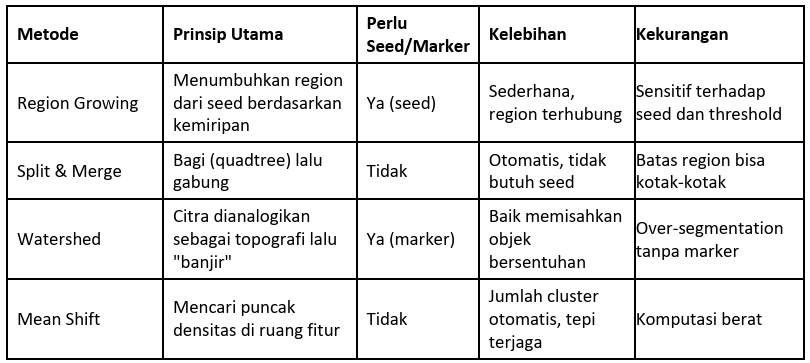

C.7 Sementasi Citra menggunakan K-Means

Pada bagian C.6, kita telah mempelajari segmentasi berbasis wilayah yang mengelompokkan piksel berdasarkan kedekatan posisi (keterhubungan) sekaligus kemiripan nilai. Region Growing, misalnya, hanya menambahkan piksel yang bersebelahan dengan region.

Segmentasi dengan clustering memakai sudut pandang lain. Citra diperlakukan sebagai kumpulan data, di mana setiap piksel adalah satu titik dengan fitur tertentu (intensitas atau warna). Piksel-piksel dengan fitur serupa dikelompokkan ke dalam cluster yang sama, tanpa mempertimbangkan letaknya di citra. Metode yang paling populer untuk tujuan ini adalah K-Means. K-Means termasuk pembelajaran tak terawasi (unsupervised learning): algoritma tidak membutuhkan contoh berlabel, cukup jumlah kelompok K yang diinginkan.

Konsep Dasar

Misalkan citra memiliki N piksel, dan setiap piksel xᵢ direpresentasikan sebagai vektor fitur. Tujuan K-Means adalah membagi N piksel menjadi K cluster C₁, C₂, ..., C_K dengan pusat (centroid) μ₁, μ₂, ..., μ_K sehingga jumlah kuadrat jarak piksel ke centroid cluster-nya minimum:
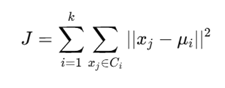

Nilai J sering disebut inertia atau within-cluster sum of squares (WCSS). Semakin kecil J, semakin rapat piksel di dalam tiap cluster.

Langkah Algoritma:
1. Tentukan K, yaitu jumlah cluster yang diinginkan.
2. Inisialisasi K centroid, secara acak atau dengan k-means++ agar penyebarannya lebih baik.
3. Penugasan: setiap piksel dimasukkan ke cluster dengan centroid terdekat.
4. Pembaruan: hitung ulang tiap centroid sebagai rata-rata seluruh piksel anggotanya.
5. Ulangi langkah 3 dan 4 sampai centroid tidak berubah (konvergen) atau iterasi maksimum tercapai.
6. Bentuk citra hasil: ganti nilai setiap piksel dengan nilai centroid cluster-nya, atau tampilkan label cluster sebagai peta segmentasi.

Pada tahap 6, citra hasil hanya memiliki K warna. Karena itu, K-Means juga dikenal sebagai teknik kuantisasi warna (color quantization).

Memilih Nilai K

K adalah parameter terpenting dan harus ditentukan oleh pengguna. Beberapa pendekatan yang umum:

- Pengetahuan tentang citra. Jika kita tahu citra terdiri dari 3 jenis objek (misalnya langit, bangunan, dan rumput), pilih K = 3
- Metode Elbow. Hitung inertia untuk beberapa nilai K, lalu cari titik "siku" pada grafik, yaitu K di mana penurunan inertia mulai melandai.
- Silhouette score. Mengukur seberapa mirip suatu piksel dengan cluster-nya dibandingkan cluster lain. Nilai mendekati 1 menunjukkan cluster yang baik.

Pemilihan K yang terlalu kecil menyatukan objek yang berbeda (under-segmentation), sedangkan K yang terlalu besar memecah satu objek menjadi banyak bagian (over-segmentation).

Kelebihan dan Keterbatasan

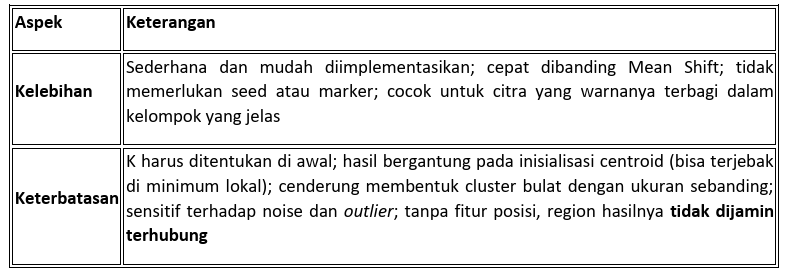

Berikut adalah code untuk penggunaan K-Means pada segmentasi citra.
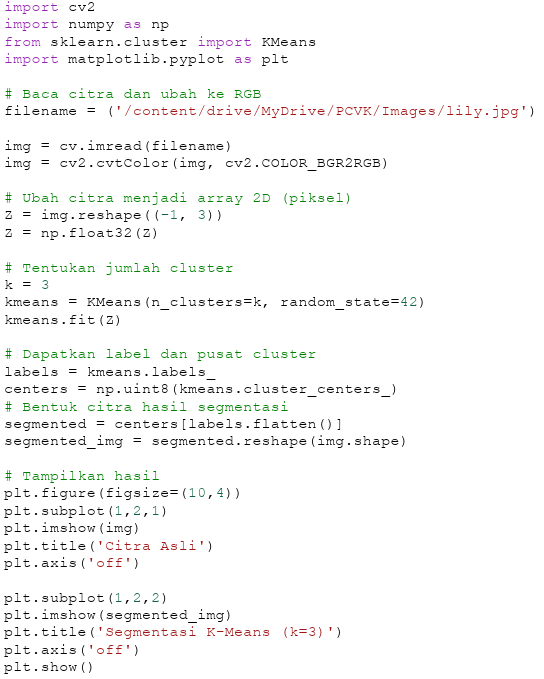



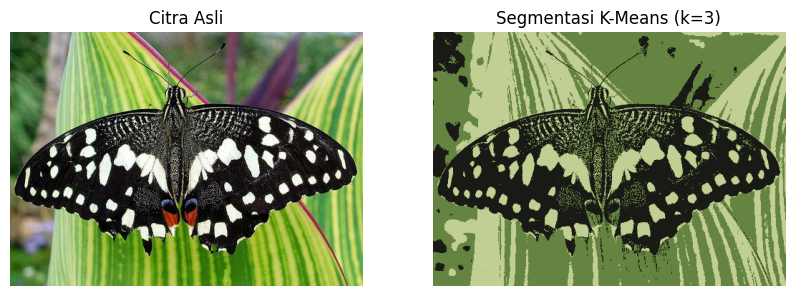

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
import os
import urllib.request

filename = '/content/drive/MyDrive/PCVK/Images/lily.jpg'

if not os.path.exists(filename):
    try:
        os.makedirs(os.path.dirname(filename), exist_ok=True)
    except:
        filename = 'lily.jpg'

    if not os.path.exists(filename):
        print("Mengunduh sampel gambar 'lily.jpg' secara otomatis...")
        url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/butterfly.jpg" # fallback sampel
        urllib.request.urlretrieve(url, filename)

img = cv2.imread(filename)
if img is None:
    filename = 'lily.jpg'
    img = cv2.imread(filename)

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

Z = img.reshape((-1, 3))
Z = np.float32(Z)

k = 3
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (k=3)')
plt.axis('off')

plt.show()

D. TUGAS PRAKTIKUM

D1. Tugas Individu
1. Buka https://colab.research.google.com/. Setelah dipastikan bahwa google Colab terhubung dengan Github Anda, lanjutkan dengan memilih repository yang telah digunakan pada praktikum minggu lalu, rename file menjadi “Week7.ipynb”.
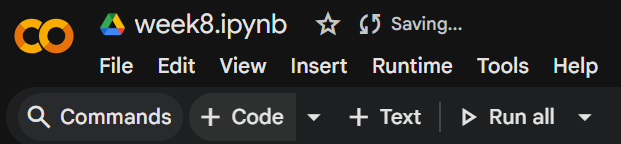

Kemudian import folder yang ada di Drive Anda dengan cara sebagai berikut
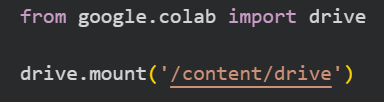

2. Import beberapa library berikut yang akan digunakan selama uji coba praktikum minggu ke-7 berikut.



In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3. Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan threshold= 200, secara manual sehingga menghasilkan tampilan seperti berikut:



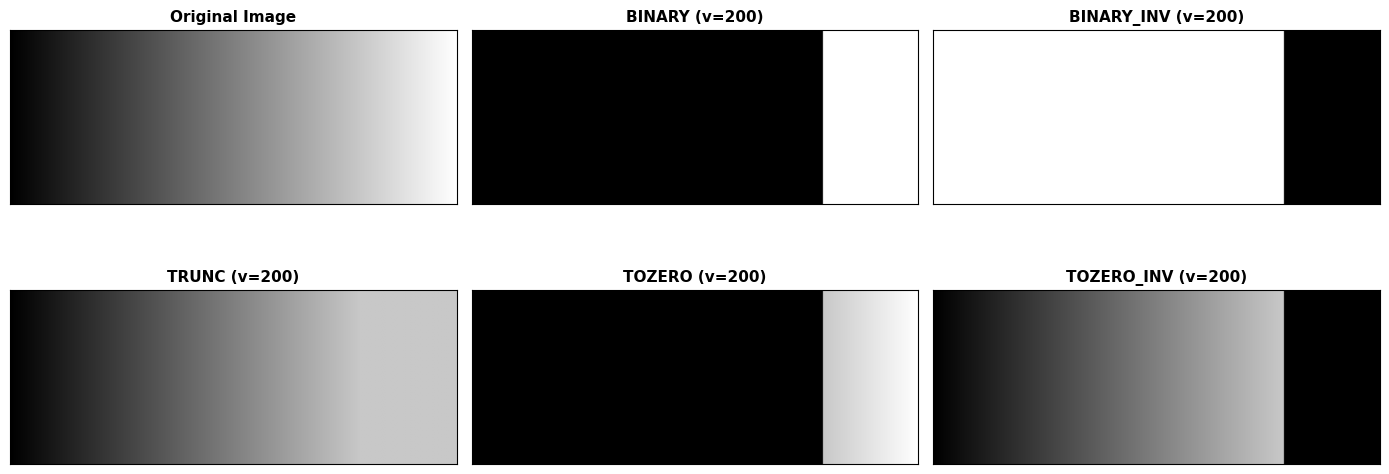

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

img = np.tile(np.arange(256, dtype=np.uint8), (100, 1))
thresh = 200
maxval = 255

ret, thresh1 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)
ret, thresh2 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY_INV)
ret, thresh3 = cv.threshold(img, thresh, maxval, cv.THRESH_TRUNC)
ret, thresh4 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO)
ret, thresh5 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO_INV)

titles = [
    'Original Image',
    'BINARY (v=200)',
    'BINARY_INV (v=200)',
    'TRUNC (v=200)',
    'TOZERO (v=200)',
    'TOZERO_INV (v=200)',
]
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]
plt.figure(figsize=(14, 6))
for i in range(len(images)):
  plt.subplot(2, 3, i + 1)
  plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
  plt.title(titles[i], fontsize=11, fontweight='bold')
  plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

4. Buat program Addaptive Threshold : adaptive mean dan adaptive Gaussian tanpa menggunakan cv.threshold(), cv.adaptiveThreshold(), maupun fungsi filter siap pakai dengan menggunakan citra Sudoku yang memiliki pencahayaan tidak merata. Ketentuan: global threshold secara manual dengan ambang 127, ukuran jendela 11 × 11, C=2, dan sigma=2 untuk Gaussian sehingga menghasilkan tampilan seperti berikut:



Memproses Adaptive Mean Manual (harap tunggu sebentar)...
Memproses Adaptive Gaussian Manual (harap tunggu sebentar)...


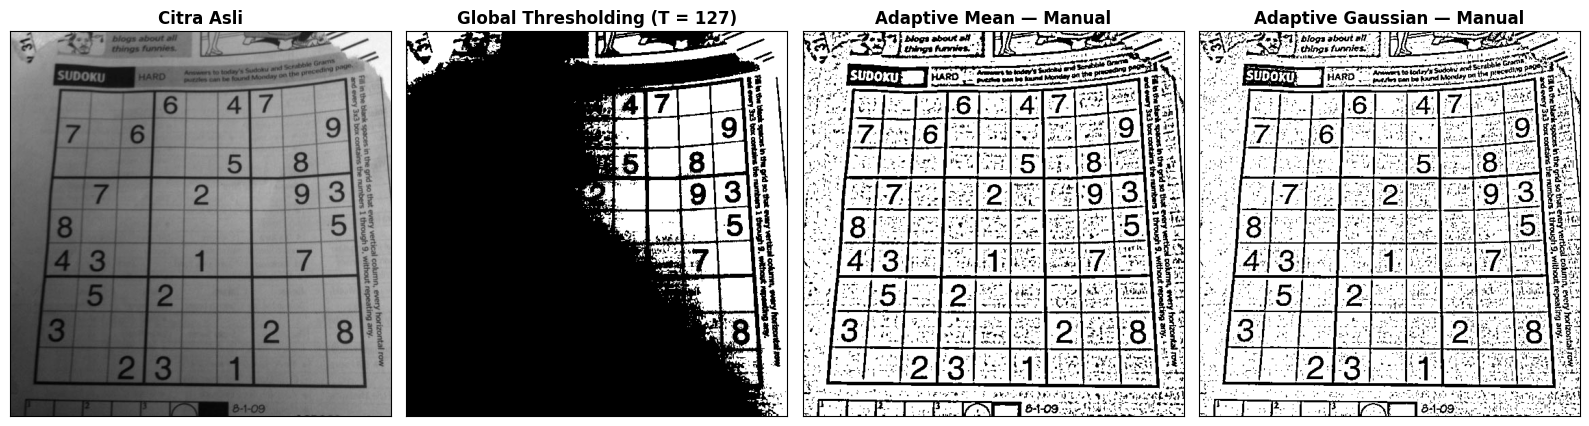

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request

filename = '/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg'
if not os.path.exists(filename):
    try:
        os.makedirs(os.path.dirname(filename), exist_ok=True)
    except:
        filename = 'sudoku-original.jpg'

    if not os.path.exists(filename):
        print("Mengunduh sampel citra 'sudoku.png'...")
        url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png"
        urllib.request.urlretrieve(url, filename)

img_raw = cv.imread(filename)
if img_raw is None:
    filename = 'sudoku-original.jpg'
    img_raw = cv.imread(filename)

gray = cv.cvtColor(img_raw, cv.COLOR_BGR2GRAY)

T = 127
global_thresh = np.zeros_like(gray)
global_thresh[gray > T] = 255
global_thresh[gray <= T] = 0

def manual_adaptive_mean(img, window_size=11, C=2):
    h, w = img.shape
    pad = window_size // 2
    padded = np.pad(img, pad, mode='reflect').astype(np.float32)
    output = np.zeros((h, w), dtype=np.uint8)

    integral = np.zeros((h + 2 * pad + 1, w + 2 * pad + 1), dtype=np.float32)
    integral[1:, 1:] = np.cumsum(np.cumsum(padded, axis=0), axis=1)

    for i in range(h):
        for j in range(w):
            r1, r2 = i, i + window_size
            c1, c2 = j, j + window_size

            total = integral[r2, c2] - integral[r1, c2] - integral[r2, c1] + integral[r1, c1]
            mean_val = total / (window_size * window_size)

            if img[i, j] > (mean_val - C):
                output[i, j] = 255
            else:
                output[i, j] = 0
    return output

def manual_gaussian_kernel(size, sigma):
    ax = np.arange(-size // 2 + 1., size // 2 + 1.)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * (sigma**2)))
    return kernel / np.sum(kernel)

def manual_adaptive_gaussian(img, window_size=11, sigma=2, C=2):
    h, w = img.shape
    pad = window_size // 2
    padded = np.pad(img, pad, mode='reflect').astype(np.float32)
    output = np.zeros((h, w), dtype=np.uint8)
    kernel = manual_gaussian_kernel(window_size, sigma)

    for i in range(h):
        for j in range(w):
            window = padded[i:i+window_size, j:j+window_size]
            gauss_mean = np.sum(window * kernel)

            if img[i, j] > (gauss_mean - C):
                output[i, j] = 255
            else:
                output[i, j] = 0
    return output

print("Memproses Adaptive Mean Manual (harap tunggu sebentar)...")
th_mean = manual_adaptive_mean(gray, window_size=11, C=2)

print("Memproses Adaptive Gaussian Manual (harap tunggu sebentar)...")
th_gauss = manual_adaptive_gaussian(gray, window_size=11, sigma=2, C=2)

titles = [
    'Citra Asli',
    'Global Thresholding (T = 127)',
    'Adaptive Mean — Manual',
    'Adaptive Gaussian — Manual'
]
images = [gray, global_thresh, th_mean, th_gauss]

plt.figure(figsize=(16, 5))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i], fontsize=12, fontweight='bold')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()